
# Experiment No. 11

## Forecast stock prices using advanced Learning models and evaluate their accuracy using a confusion matrix.
### Aim
To predict future stock prices using Long Short-Term Memory (LSTM) networks, a type of recurrent neural network (RNN) capable of learning long-term dependencies in time-series data.


Import required Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

Load the dataset

In [3]:
df = pd.read_csv("AAPL.csv")
print(df.head())
print(df.info())

         Date      Open      High       Low     Close  Adj Close     Volume
0  1980-12-12  0.128348  0.128906  0.128348  0.128348   0.100178  469033600
1  1980-12-15  0.122210  0.122210  0.121652  0.121652   0.094952  175884800
2  1980-12-16  0.113281  0.113281  0.112723  0.112723   0.087983  105728000
3  1980-12-17  0.115513  0.116071  0.115513  0.115513   0.090160   86441600
4  1980-12-18  0.118862  0.119420  0.118862  0.118862   0.092774   73449600
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10468 entries, 0 to 10467
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       10468 non-null  object 
 1   Open       10468 non-null  float64
 2   High       10468 non-null  float64
 3   Low        10468 non-null  float64
 4   Close      10468 non-null  float64
 5   Adj Close  10468 non-null  float64
 6   Volume     10468 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 572.6+ KB
None


Extract the closing price

In [4]:
data = df[['Close']].copy()

data = data.dropna()

print(data.head())
print("Total Records:", len(data))

      Close
0  0.128348
1  0.121652
2  0.112723
3  0.115513
4  0.118862
Total Records: 10468


Visualize historical stock prices

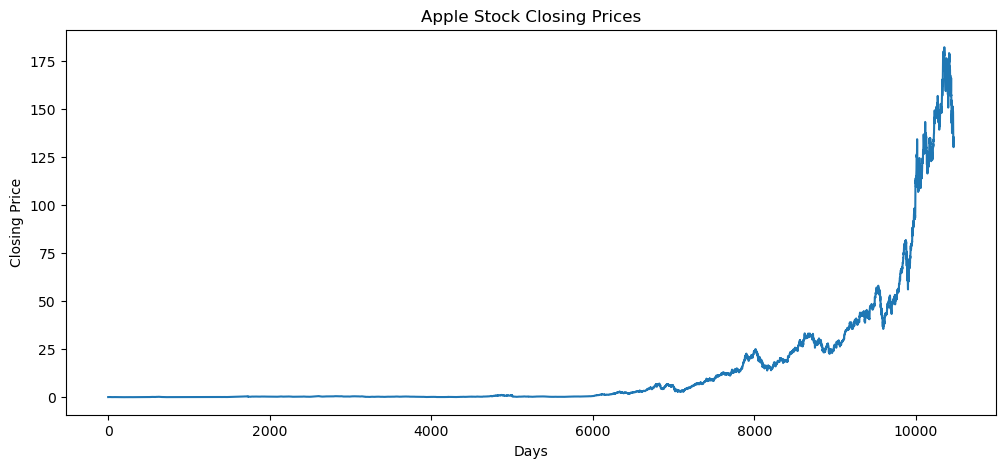

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(data['Close'])

plt.title("Apple Stock Closing Prices")
plt.xlabel("Days")
plt.ylabel("Closing Price")

plt.show()

Normalize the data

In [6]:
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(data)

print(scaled_data[:5])

[[0.00043548]
 [0.00039868]
 [0.00034961]
 [0.00036495]
 [0.00038335]]


Split data into training and testing sets

In [24]:
training_size = int(len(data) * 0.8)

train_raw = data.iloc[:training_size].values
test_raw = data.iloc[training_size:].values

scaler = MinMaxScaler(feature_range=(0, 1))

train_data = scaler.fit_transform(train_raw)
test_data = scaler.transform(test_raw)

print("Training data:", len(train_data))
print("Testing data:", len(test_data))

Training data: 8374
Testing data: 2094


Create sequences of 60 days

In [25]:
time_step = 60

x_train = []
y_train = []

for i in range(time_step, len(train_data)):
    x_train.append(train_data[i-time_step:i, 0])
    y_train.append(train_data[i, 0])
    
x_train = np.array(x_train)
y_train = np.array(y_train)

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

x_train shape: (8314, 60)
y_train shape: (8314,)


Prepare testing sequences

In [26]:
combined_data = np.concatenate(
    (train_data[-time_step:], test_data),
    axis = 0
)
 
x_test = []
y_test = []

for i in range(time_step, len(combined_data)):
    x_test.append(combined_data[i-time_step:i, 0])
    y_test.append(combined_data[i, 0])
    
x_test = np.array(x_test)
y_test = np.array(y_test)

print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_test shape: (2094, 60)
y_test shape: (2094,)


Reshape data for LSTM

In [27]:
x_train = x_train.reshape(
    x_train.shape[0], x_train.shape[1], 1
)

x_test = x_test.reshape(
    x_test.shape[0], x_test.shape[1], 1
)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (8314, 60, 1)
Testing shape: (2094, 60, 1)


Build the LSTM model

In [28]:
model = Sequential()

model.add(LSTM(
    units=50,
    return_sequences=True,
    input_shape=(60, 1)
))

model.add(Dropout(0.2))

model.add(LSTM(
    units=50,
    return_sequences=False
))

model.add(Dropout(0.2))

model.add(Dense(units=25))

model.add(Dense(units=1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()

d:\Anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

Train the model

In [29]:
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - loss: 3.2023e-04 - val_loss: 8.9182e-04
Epoch 2/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - loss: 9.8771e-05 - val_loss: 6.7932e-04
Epoch 3/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - loss: 8.6877e-05 - val_loss: 6.6702e-04
Epoch 4/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - loss: 8.4577e-05 - val_loss: 0.0011
Epoch 5/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 12s 49ms/step - loss: 8.6676e-05 - val_loss: 0.0062
Epoch 6/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 22s 55ms/step - loss: 7.7375e-05 - val_loss: 5.1584e-04
Epoch 7/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 16s 66ms/step - loss: 9.0312e-05 - val_loss: 7.6950e-04
Epoch 8/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - loss: 9.3632e-05 - val_loss: 4.5811e-04
Epoch 9/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - loss: 8.2445e-05 - val_loss: 4.9696e-04
Epoch 10/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - loss: 7.8970e-05 - val_loss: 4.0503e-04
Epoch 11/20
234/234 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms

Predict stock prices

In [30]:
predictions = model.predict(x_test)

predicted_prices = scaler.inverse_transform(predictions)

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

print("Predicted Prices:")
print(predicted_prices[:5])

print("Actual Prices:")
print(actual_prices[:5])

66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step
Predicted Prices:
[[17.541044]
 [17.417423]
 [17.3773  ]
 [17.370018]
 [17.388628]]
Actual Prices:
[[18.476786]
 [18.845358]
 [18.794287]
 [18.848572]
 [18.972857]]


Evaluate model using MSE and RMSE

In [31]:
mse = mean_squared_error(
    actual_prices,
    predicted_prices
)

rmse = np.sqrt(mse)

print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)

Mean Squared Error (MSE): 1651.3343998673683
Root Mean Squared Error (RMSE): 40.63661403054354


Visualize actual vs predicted prices

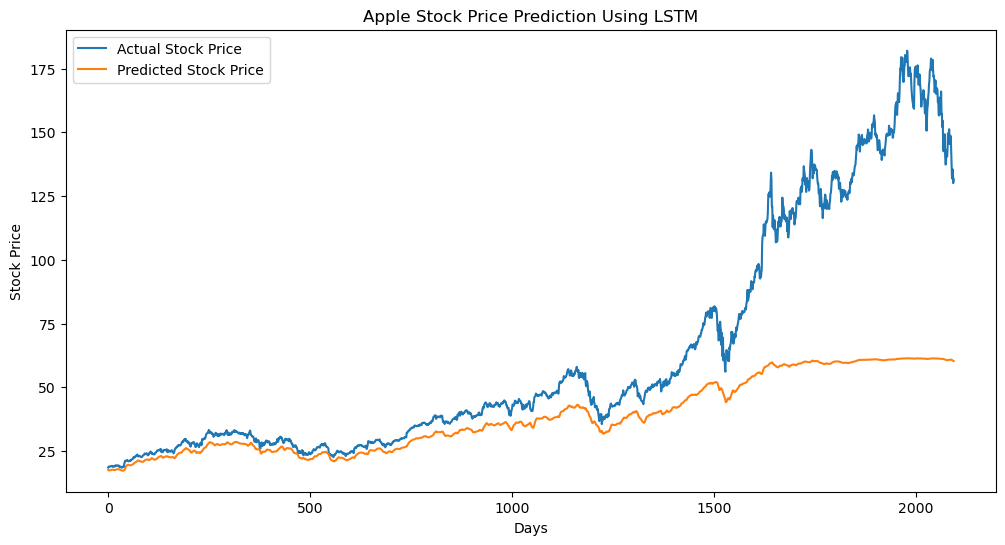

In [32]:
plt.figure(figsize=(12, 6))

plt.plot(actual_prices, label='Actual Stock Price')

plt.plot(predicted_prices, label='Predicted Stock Price')

plt.title("Apple Stock Price Prediction Using LSTM")
plt.xlabel("Days")
plt.ylabel("Stock Price")

plt.legend()
plt.show()

Generate confusion matrix

In [33]:
# Actual price movement
actual_direction = (
    actual_prices[1:] > actual_prices[:-1]
).astype(int)

# Predicted price movement
predicted_direction = (
    predicted_prices[1:] > actual_prices[:-1]
).astype(int)

# Generate Confusion Matrix
cm = confusion_matrix(
    actual_direction,
    predicted_direction,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    actual_direction,
    predicted_direction,
    labels=[0, 1],
    target_names=['DOWN', 'UP'],
    zero_division=0
))

Confusion Matrix:
[[ 987    0]
 [1106    0]]

Classification Report:
              precision    recall  f1-score   support

        DOWN       0.47      1.00      0.64       987
          UP       0.00      0.00      0.00      1106

    accuracy                           0.47      2093
   macro avg       0.24      0.50      0.32      2093
weighted avg       0.22      0.47      0.30      2093



Plot the confusion matrix

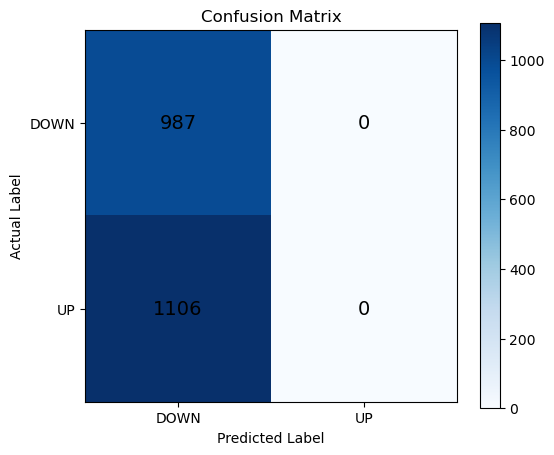

In [34]:
plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap='Blues')

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ['DOWN', 'UP'])
plt.yticks([0, 1], ['DOWN', 'UP'])

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i, j],
            ha='center',
            va='center',
            fontsize=14
        )

plt.colorbar()
plt.show()

Plot model training and validation loss

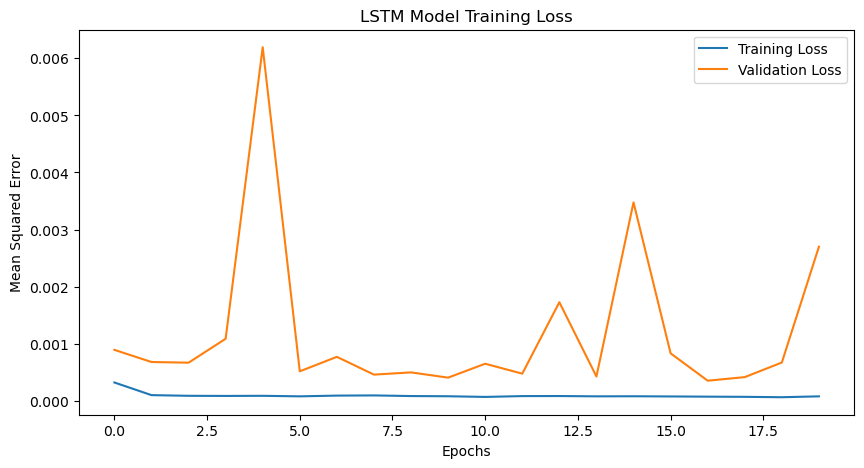

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label = 'Training Loss')

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("LSTM Model Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")

plt.legend()
plt.show()

### Conclusion
The Apple stock price forecasting experiment was successfully implemented using an LSTM neural network. Historical stock price data was preprocessed, normalized, and converted into 60-day sequences for training. The model predicted future closing prices, and its performance was evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and a Confusion Matrix for UP/DOWN price movement classification. The actual and predicted stock prices were visualized to analyze the model's performance. Thus, LSTM can be used to learn patterns from time-series data and forecast stock prices.